In [57]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             precision_recall_curve, balanced_accuracy_score)

import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.callbacks import EarlyStopping, ModelCheckpoint

from preprocessing4 import prepare_data

In [58]:
batch_size = 20
lr = 0.003
strat="doy_window_median"
split_t="recent20"

scaler_name = "minmax"
SCALERS = {"minmax": MinMaxScaler, "standard": StandardScaler, "none": None}

class_wei = None

# Prepare data

In [59]:
X_train_val, y_train_val, X_test, y_test = prepare_data(strat, 
                                                        split_t, 
                                                        one_hot_cluster=True, 
                                                        sin_doy=True)

In [60]:
# Split train and validation: _train_val -> _train , _val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15, random_state=42, stratify=y_train_val)

In [61]:
# Scaling: fit on train only, continuous columns only

# Continuous columns only (> 2 distinct values)
num_names = [c for c in X_train.columns if X_train[c].nunique() > 2]

X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()

# Scaling: fit on train only
if SCALERS[scaler_name] is not None:
    scaler = SCALERS[scaler_name]().fit(X_train[num_names])
    for A in (X_train, X_val, X_test):
        A[num_names] = scaler.transform(A[num_names])

In [62]:
display(X_train.describe())
display(X_val.describe())
display(X_test.describe())

,SST,UI,YDOY,sin_doy,CHL_log,CHL_uncertainty,cluster_0,cluster_1,cluster_2,cluster_4,cluster_5
count,769.000000,769.000000,769.000000,769.000000,769.000000,769.000000,769.000000,769.000000,769.000000,769.000000,769.000000
mean,0.363250,0.514272,0.481903,0.491998,0.438370,0.353686,0.481144,0.011704,0.050715,0.282185,0.174252
std,0.179351,0.095854,0.346175,0.360721,0.142899,0.202658,0.499970,0.107618,0.219558,0.450356,0.379573
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.230850,0.490105,0.158036,0.129386,0.359631,0.214311,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.339979,0.508407,0.442055,0.482789,0.401347,0.306512,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.469045,0.545617,0.826007,0.864782,0.501890,0.422605,1.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


,SST,UI,YDOY,sin_doy,CHL_log,CHL_uncertainty,cluster_0,cluster_1,cluster_2,cluster_4,cluster_5
count,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000,136.000000
mean,0.342325,0.509056,0.468522,0.505139,0.409700,0.367153,0.382353,0.014706,0.080882,0.345588,0.176471
std,0.177317,0.091878,0.333780,0.373416,0.146856,0.208705,0.487759,0.120818,0.273662,0.477318,0.382629
min,0.051417,0.082151,0.000000,0.000111,0.046069,0.073784,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.216422,0.488261,0.153443,0.134485,0.333821,0.208158,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.307450,0.511828,0.484966,0.454874,0.393117,0.314937,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.449370,0.545625,0.783333,0.893491,0.473573,0.481915,1.000000,0.000000,0.000000,1.000000,0.000000
max,0.983211,0.865401,0.998889,1.000000,0.980665,0.888782,1.000000,1.000000,1.000000,1.000000,1.000000


,SST,UI,YDOY,sin_doy,CHL_log,CHL_uncertainty,cluster_0,cluster_1,cluster_2,cluster_4,cluster_5
count,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.000000,87.0,87.000000,87.000000,87.000000
mean,0.390069,0.535314,0.396342,0.480571,0.387342,0.387887,0.379310,0.0,0.160920,0.241379,0.218391
std,0.172066,0.083128,0.351991,0.343189,0.170413,0.279437,0.488028,0.0,0.369587,0.430400,0.415549
min,0.014690,0.256646,0.000148,0.005657,0.068875,0.071377,0.000000,0.0,0.000000,0.000000,0.000000
25%,0.245540,0.498484,0.083227,0.118066,0.274497,0.140648,0.000000,0.0,0.000000,0.000000,0.000000
50%,0.372508,0.524020,0.262530,0.491393,0.385238,0.273471,0.000000,0.0,0.000000,0.000000,0.000000
75%,0.522560,0.566099,0.792204,0.814384,0.479712,0.627829,1.000000,0.0,0.000000,0.000000,0.000000
max,0.778594,0.818302,1.000000,0.996116,0.872813,1.035147,1.000000,0.0,1.000000,1.000000,1.000000


In [63]:
pd.concat({"train": X_train.describe().T,
           "val":   X_val.describe().T,
           "test":  X_test.describe().T}, axis=1)[["train", "val", "test"]].round(3)

train                                                 val  \
                 count   mean    std  min    25%    50%    75%  max  count   
SST              769.0  0.363  0.179  0.0  0.231  0.340  0.469  1.0  136.0   
UI               769.0  0.514  0.096  0.0  0.490  0.508  0.546  1.0  136.0   
YDOY             769.0  0.482  0.346  0.0  0.158  0.442  0.826  1.0  136.0   
sin_doy          769.0  0.492  0.361  0.0  0.129  0.483  0.865  1.0  136.0   
CHL_log          769.0  0.438  0.143  0.0  0.360  0.401  0.502  1.0  136.0   
CHL_uncertainty  769.0  0.354  0.203  0.0  0.214  0.307  0.423  1.0  136.0   
cluster_0        769.0  0.481  0.500  0.0  0.000  0.000  1.000  1.0  136.0   
cluster_1        769.0  0.012  0.108  0.0  0.000  0.000  0.000  1.0  136.0   
cluster_2        769.0  0.051  0.220  0.0  0.000  0.000  0.000  1.0  136.0   
cluster_4        769.0  0.282  0.450  0.0  0.000  0.000  1.000  1.0  136.0   
cluster_5        769.0  0.174  0.380  0.0  0.000  0.000  0.000  1.0  136.0   

                        ...                test                              \
                  mean  ...    75%    max count   mean    std    min    25%   
SST              0.342  ...  0.449  0.983  87.0  0.390  0.172  0.015  0.246   
UI               0.509  ...  0.546  0.865  87.0  0.535  0.083  0.257  0.498   
YDOY             0.469  ...  0.783  0.999  87.0  0.396  0.352  0.000  0.083   
sin_doy          0.505  ...  0.893  1.000  87.0  0.481  0.343  0.006  0.118   
CHL_log          0.410  ...  0.474  0.981  87.0  0.387  0.170  0.069  0.274   
CHL_uncertainty  0.367  ...  0.482  0.889  87.0  0.388  0.279  0.071  0.141   
cluster_0        0.382  ...  1.000  1.000  87.0  0.379  0.488  0.000  0.000   
cluster_1        0.015  ...  0.000  1.000  87.0  0.000  0.000  0.000  0.000   
cluster_2        0.081  ...  0.000  1.000  87.0  0.161  0.370  0.000  0.000   
cluster_4        0.346  ...  1.000  1.000  87.0  0.241  0.430  0.000  0.000   
cluster_5        0.176  ...  0.000  1.000  87.0  0.218  0.416  0.000  0.000   

                                      
                   50%    75%    max  
SST              0.373  0.523  0.779  
UI               0.524  0.566  0.818  
YDOY             0.263  0.792  1.000  
sin_doy          0.491  0.814  0.996  
CHL_log          0.385  0.480  0.873  
CHL_uncertainty  0.273  0.628  1.035  
cluster_0        0.000  1.000  1.000  
cluster_1        0.000  0.000  0.000  
cluster_2        0.000  0.000  1.000  
cluster_4        0.000  0.000  1.000  
cluster_5        0.000  0.000  1.000  

[11 rows x 24 columns]

In [64]:
# Convert for Keras
feature_names = X_train.columns.tolist()
X_train, X_val, X_test = (A.to_numpy(dtype="float32") for A in (X_train, X_val, X_test))


# MLP's

In [65]:
THRESHOLD = None

# A
dropA=0.0
RegulA=True
RegA=0

epochA=50
patA=10


#B
dropB=0.4
RegulB=True
RegB=1e-4

epochB=50
patB=40

## NN

### Functions

In [66]:
def build_mlp(units, dropout=0.0, name="mlp", Regul=True, Reg=1e-4, seed=42):
    keras.utils.set_random_seed(seed)          # same initial weights every time
    m = Sequential(name=name)
    m.add(Input(shape=(X_test.shape[1],)))
    for u in units:
        if Regul:
            m.add(Dense(u, activation="relu", kernel_regularizer=keras.regularizers.l2(Reg)))
        else:
            m.add(Dense(u, activation="relu"))
        if dropout > 0:
            m.add(Dropout(dropout))
    m.add(Dense(1, activation="sigmoid"))          # binary output
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m


def train(model, name, n_epochs, pat):
    cbs = [EarlyStopping(monitor="val_auc", mode="max", patience=pat,
              start_from_epoch=20, restore_best_weights=True),
           ModelCheckpoint(f"best_{name}.keras", monitor="val_auc", mode="max", save_best_only=True)]
    return model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size,
                     validation_data=(X_val, y_val), callbacks=cbs,
                     class_weight=class_wei, verbose=1)

### Neural Network 1

In [67]:
# Model A: small (like the example notebook)
model_A = build_mlp([16, 8], 
                    dropout=dropA, 
                    name="NN_A", 
                    Regul=RegulA, 
                    Reg=RegA)

model_A.summary()

hist_A = train(model_A, "NN_A", epochA, pat=patA)

Model: "NN_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8817 - auc: 0.5512 - loss: 0.3982 - val_accuracy: 0.8824 - val_auc: 0.5932 - val_loss: 0.3582
Epoch 2/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8817 - auc: 0.7367 - loss: 0.3345 - val_accuracy: 0.8824 - val_auc: 0.6255 - val_loss: 0.3550
Epoch 3/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8817 - auc: 0.7615 - loss: 0.3225 - val_accuracy: 0.8824 - val_auc: 0.6552 - val_loss: 0.3536
Epoch 4/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8817 - auc: 0.7773 - loss: 0.3140 - val_accuracy: 0.8824 - val_auc: 0.6760 - val_loss: 0.3484
Epoch 5/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8817 - auc: 0.7893 - loss: 0.3076 - val_accuracy: 0.8824 - val_auc: 0.6984 - val_loss: 0.3398
Epoch 6/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8817 - auc: 0.7991 - loss: 0.3028 - val_accuracy: 0.8824 - val_auc: 0.7307 - val_loss: 0.3302
Epoch 7/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/ste

### Neural Network 2

In [68]:
model_B = build_mlp([64, 32], 
                    dropout=dropB, 
                    name="NN_B", 
                    Regul=RegulB, 
                    Reg=RegB)

model_B.summary()

hist_B = train(model_B, "NN_B", epochB, pat=patB)

Model: "NN_B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_27 (Dense)                │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8505 - auc: 0.5041 - loss: 0.4581 - val_accuracy: 0.8824 - val_auc: 0.5969 - val_loss: 0.3722
Epoch 2/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8817 - auc: 0.6313 - loss: 0.3653 - val_accuracy: 0.8824 - val_auc: 0.6865 - val_loss: 0.3475
Epoch 3/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8817 - auc: 0.7540 - loss: 0.3278 - val_accuracy: 0.8824 - val_auc: 0.7292 - val_loss: 0.3328
Epoch 4/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8817 - auc: 0.7761 - loss: 0.3163 - val_accuracy: 0.8824 - val_auc: 0.7573 - val_loss: 0.3255
Epoch 5/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8817 - auc: 0.7770 - loss: 0.3193 - val_accuracy: 0.8824 - val_auc: 0.7688 - val_loss: 0.3214
Epoch 6/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8817 - auc: 0.7688 - loss: 0.3222 - val_accuracy: 0.8824 - val_auc: 0.7721 - val_loss: 0.3191
Epoch 7/50
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/ste

## Plots and Metrics

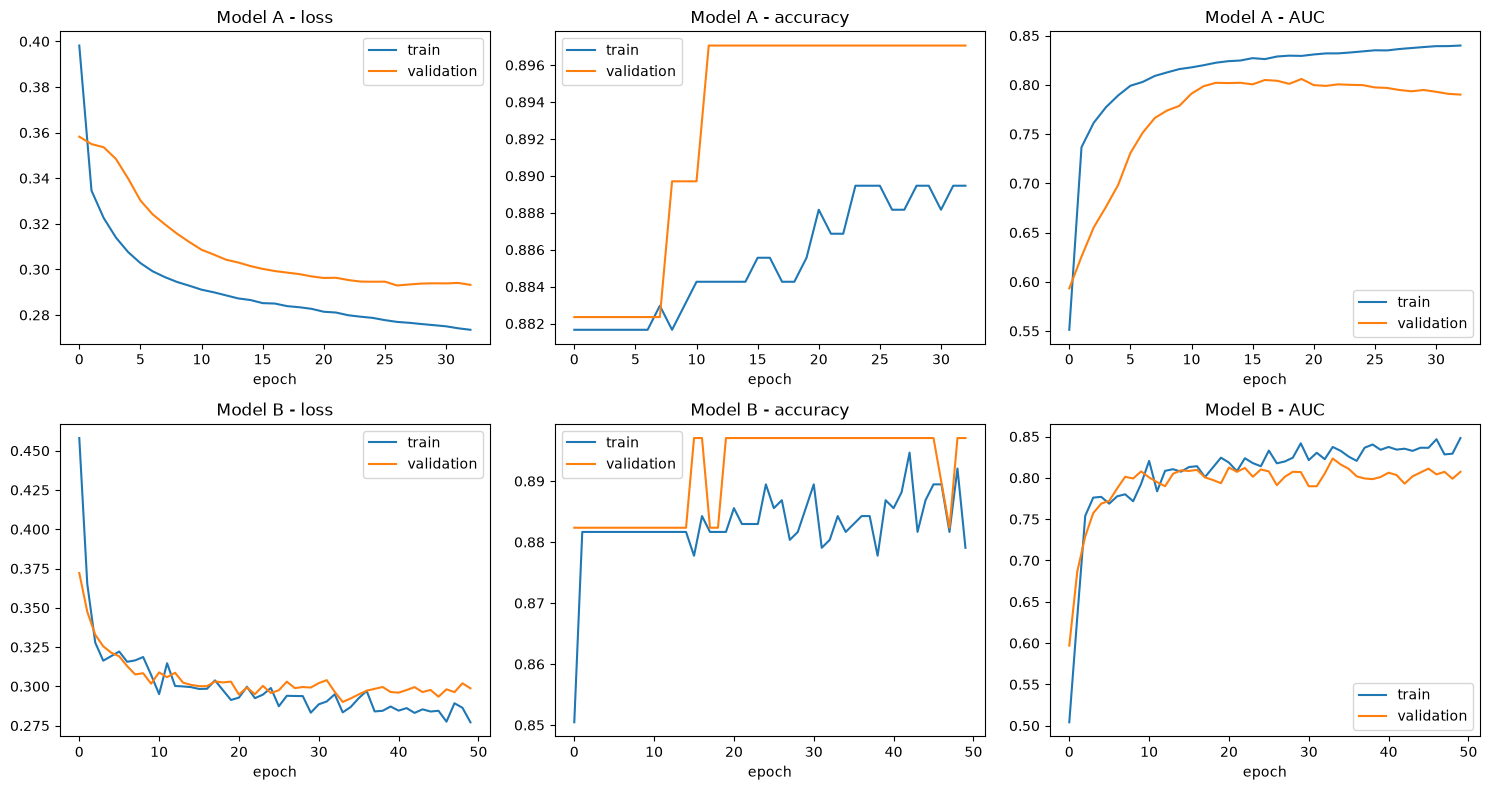

In [69]:
# Training curves: loss, accuracy and AUC (train vs validation)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for row, (h, title) in enumerate([(hist_A, "Model A"), (hist_B, "Model B")]):
    for col, (metric, label) in enumerate([("loss", "loss"), ("accuracy", "accuracy"), ("auc", "AUC")]):
        ax[row, col].plot(h.history[metric], label="train")
        ax[row, col].plot(h.history["val_" + metric], label="validation")
        ax[row, col].set_title(f"{title} - {label}")
        ax[row, col].set_xlabel("epoch")
        ax[row, col].legend()
plt.tight_layout(); plt.show()

In [70]:
def report(model, name):
    ytr, yva, yte = y_train.astype(int), y_val.astype(int), y_test.astype(int)
    p_tr = model.predict(X_train, verbose=0).ravel()
    p_va = model.predict(X_val,   verbose=0).ravel()
    p_te = model.predict(X_test,  verbose=0).ravel()

    if THRESHOLD is None:
        prec, rec, thr = precision_recall_curve(yva, p_va)
        f1 = 2 * prec * rec / (prec + rec + 1e-12)
        t = float(thr[np.argmax(f1[:-1])])
    else:
        t = THRESHOLD

    pred = lambda p: (p >= t).astype(int)

    print(f"===== {name} =====")
    for label, y, p in [("Train      ", ytr, p_tr), ("Validation ", yva, p_va), ("Test       ", yte, p_te)]:
        print(f"{label} accuracy = {accuracy_score(y, pred(p)):.4f} | "
              f"balanced acc = {balanced_accuracy_score(y, pred(p)):.4f} | "
              f"AUC = {roc_auc_score(y, p):.4f}")

    print(f"\nThreshold used: {t:.3f}")

    yp = pred(p_te)
    print(f"\n* accuracy on test         : {accuracy_score(yte, yp):.4f}")
    print(f"* balanced accuracy on test: {balanced_accuracy_score(yte, yp):.4f}")
    print(f"* precision on test        : {precision_score(yte, yp, zero_division=0):.4f}")
    print(f"* recall on test           : {recall_score(yte, yp, zero_division=0):.4f}")
    print(f"* f1-score on test         : {f1_score(yte, yp, zero_division=0):.4f}")

    print("\nConfusion matrix (rows = true 0/1, cols = predicted 0/1):")
    print(confusion_matrix(yte, yp))
    print()

report(model_A, "NN_A")
report(model_B, "NN_B")

===== NN_A =====
Train       accuracy = 0.8804 | balanced acc = 0.5992 | AUC = 0.8373
Validation  accuracy = 0.9044 | balanced acc = 0.6479 | AUC = 0.7979
Test        accuracy = 0.7586 | balanced acc = 0.5812 | AUC = 0.8571

Threshold used: 0.408

* accuracy on test         : 0.7586
* balanced accuracy on test: 0.5812
* precision on test        : 0.5000
* recall on test           : 0.2381
* f1-score on test         : 0.3226

Confusion matrix (rows = true 0/1, cols = predicted 0/1):
[[61  5]
 [16  5]]

===== NN_B =====
Train       accuracy = 0.8687 | balanced acc = 0.7400 | AUC = 0.8517
Validation  accuracy = 0.8529 | balanced acc = 0.7000 | AUC = 0.8224
Test        accuracy = 0.7931 | balanced acc = 0.7338 | AUC = 0.8470

Threshold used: 0.269

* accuracy on test         : 0.7931
* balanced accuracy on test: 0.7338
* precision on test        : 0.5652
* recall on test           : 0.6190
* f1-score on test         : 0.5909

Confusion matrix (rows = true 0/1, cols = predicted 0/1):
[[56 1